# Full interaction (Heisenberg + RKKY)

In [ ]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice
using MX2RKKY.observables

using Random: MersenneTwister
using Statistics: mean, std
using HDF5

using PyPlot; const plt = PyPlot;

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


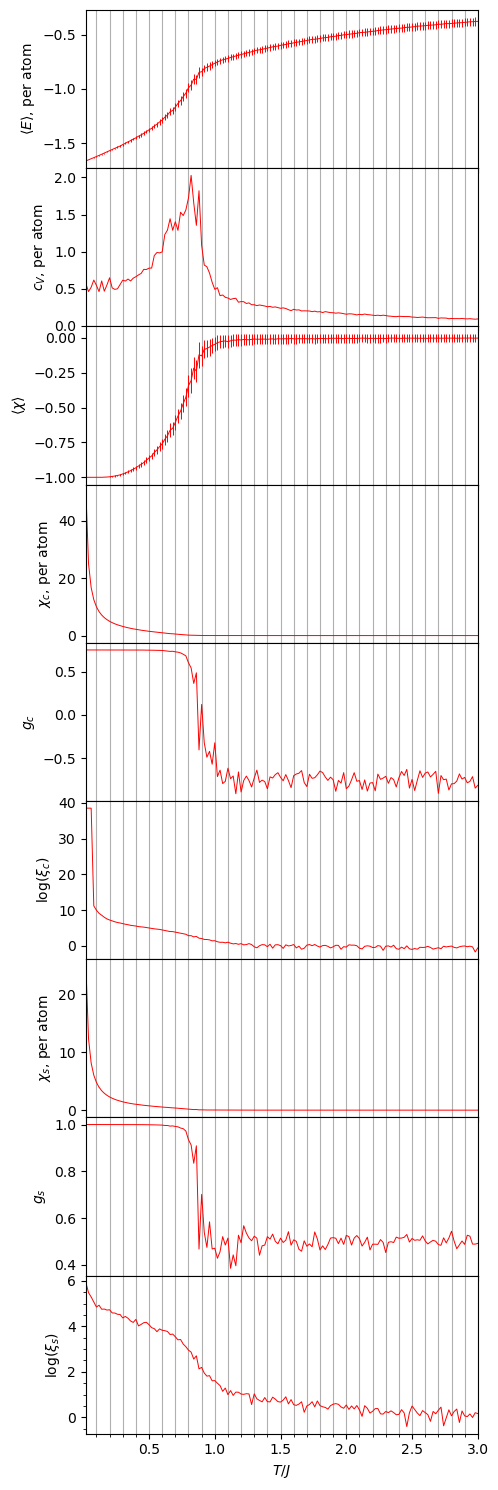

In [10]:
L = 24

fig = plt.figure(figsize=(5, 15))
let gs = plt.matplotlib.gridspec.GridSpec(9, 1, hspace=0), i = 1, ax = plt.subplot(gs[1])
    global add_plot_panel
    function add_plot_panel(;xticks=false)
        if i > 1
            ax = plt.subplot(gs[i], sharex=ax)
        end
        ax.grid(axis="x", which="both")
        if !xticks
            plt.setp(ax.get_xticklabels(), visible=false)
        end
        i += 1
        return ax
    end
end

h5open("../../RKKY_temperature_scan/RKKY_T_scan_L$(L).h5", "r") do ar
    params = read(ar, "params")
    T_range = params["T_range"]

    # Energy and specific heat
    E = [ar["/T$(T)/E"][] for T in T_range]
    E_avg = avg_energy.(E)
    E_var = var_energy.(E)
    cV = specific_heat.(E, 1.0 ./ T_range)

    ax = add_plot_panel()
    ax.errorbar(collect(T_range), E_avg / L^2, yerr=E_var / L^2, lw=0.7, color="red")
    ax.set_ylabel(raw"$\langle E\rangle$, per atom")

    ax = add_plot_panel()
    ax.plot(collect(T_range), cV / L^2, lw=0.7, color="red")
    ax.set_ylabel(raw"$c_V$, per atom")

    # Chirality susceptibility and Binder cumulant
    χ = [ar["/T$(T)/chi"][] for T in T_range]
    χ_at_q_min = [ar["/T$(T)/chi_at_q_min"][] for T in T_range]
    
    χ_avg = avg_chirality.(χ)
    χ_var = var_chirality.(χ)
    χ_susc = susc_chirality.(χ, L^2, 1.0 ./ T_range)
    χ_binder = binder_chirality.(χ)
    χ_cl = corr_length_chirality.(χ, χ_at_q_min, L)

    ax = add_plot_panel()
    ax.errorbar(collect(T_range), χ_avg, χ_var, lw=0.7, color="red")
    ax.set_ylabel(raw"$\langle\chi\rangle$")

    ax = add_plot_panel()
    ax.plot(collect(T_range), χ_susc / L^2, lw=0.7, color="red")
    ax.set_ylabel(raw"$\chi_c$, per atom")

    ax = add_plot_panel()
    ax.plot(collect(T_range), χ_binder, lw=0.7, color="red")
    ax.set_ylabel(raw"$g_c$")

    ax = add_plot_panel()
    ax.plot(collect(T_range), log.(abs.(χ_cl)), lw=0.7, color="red")
    ax.set_ylabel(raw"$\log(\xi_c)$")

    # Magnetization at K-point: susceptibility, Binder cumulant and correlation length
    m_at_K = [ar["/T$(T)/m_at_K"][] for T in T_range]
    m_at_K_q_min = [ar["/T$(T)/m_at_K_q_min"][] for T in T_range]
    
    m_susc = susc_spin_K.(m_at_K, L^2, 1.0 ./ T_range)
    m_binder = binder_spin_K.(m_at_K)
    m_cl = corr_length_spin_K.(m_at_K, m_at_K_q_min, L)

    ax = add_plot_panel()
    ax.plot(collect(T_range), m_susc / L^2, lw=0.7, color="red")
    ax.set_ylabel(raw"$\chi_s$, per atom")

    ax = add_plot_panel()
    ax.plot(collect(T_range), m_binder, lw=0.7, color="red")
    ax.set_ylabel(raw"$g_s$")

    ax = add_plot_panel(xticks=true)
    ax.plot(collect(T_range), log.(abs.(m_cl)), lw=0.7, color="red")
    ax.set_ylabel(raw"$\log(\xi_s)$")

    ax.set_xlim((first(T_range), last(T_range)))
    ax.set_xlabel(raw"$T/J$")
    ax.minorticks_on()
    plt.show()
    plt.tight_layout()
    fig.savefig("rkky_temp_scan.pdf")
end